# Fake Face Detector Evaluation
Evaluate a MobileNetV2-based CNN model using a labeled test dataset.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
from sklearn.metrics import roc_curve, auc

2025-05-21 14:19:07.901935: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1747837148.208694      35 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1747837148.298708      35 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


## Load Trained Model (.h5)


In [2]:
model = load_model('/kaggle/input/fp_modelv2/tensorflow2/default/1/FP_fake_image_detector_modelV2.h5')

2025-05-21 14:19:24.585066: E external/local_xla/xla/stream_executor/cuda/cuda_driver.cc:152] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


## Load and Preprocess Test Images


In [3]:
test_dir = '/kaggle/input/140k-real-and-fake-faces/real_vs_fake/real-vs-fake/test'

# Preprocessing the test images the same way you did for training
img_size = (128, 128)  # use the input size your model was trained on

test_datagen = ImageDataGenerator(rescale=1./255)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=img_size,
    batch_size=32,
    class_mode='binary',
    shuffle=False  # Important to not shuffle so labels match predictions
)

Found 20000 images belonging to 2 classes.


## Predict Labels on Test Set
Get predicted probabilities and convert them to binary labels.

In [4]:
pred_probs = model.predict(test_generator)
pred_labels = (pred_probs > 0.5).astype(int).reshape(-1)  # Binary classification
true_labels = test_generator.classes

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


625/625 ━━━━━━━━━━━━━━━━━━━━ 155s 246ms/step


## Confusion Matrix
Visualize model performance with a confusion matrix.

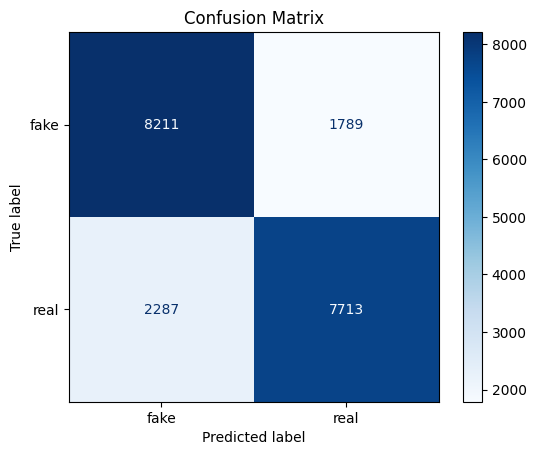

In [5]:
# Confusion Matrix
cm = confusion_matrix(true_labels, pred_labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=test_generator.class_indices)
disp.plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix')
plt.show()

## Classification Report
Shows Precision, Recall, F1-score, and Accuracy.

In [6]:
# Classification Report
print("Classification Report:\n")
print(classification_report(true_labels, pred_labels, target_names=test_generator.class_indices.keys()))

Classification Report:

              precision    recall  f1-score   support

        fake       0.78      0.82      0.80     10000
        real       0.81      0.77      0.79     10000

    accuracy                           0.80     20000
   macro avg       0.80      0.80      0.80     20000
weighted avg       0.80      0.80      0.80     20000



## ROC Curve and AUC Score
Visualize how well the model separates the classes.

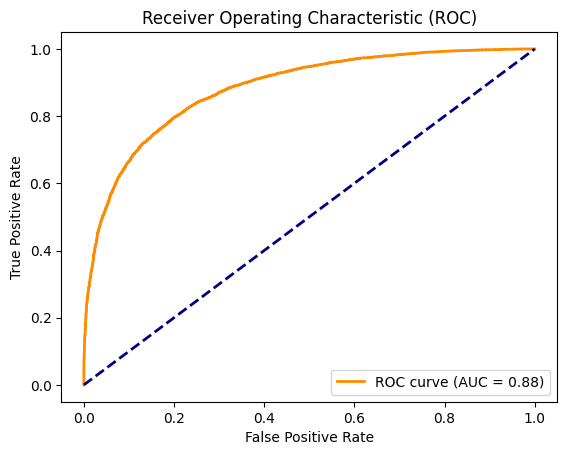

In [7]:
fpr, tpr, _ = roc_curve(true_labels, pred_probs)
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc='lower right')
plt.show()